**Breast Cancer Classification Using Machine Learning**

**Implementasi Machine Learning Menggunakan Python dan Google Colab**

Klasifikasi kanker payudara dilakukan dengan membangun model Machine Learning menggunakan algoritma Logistic Regression dan Random Forest Classifier. Dataset yang digunakan adalah Breast Cancer Wisconsin Dataset yang tersedia pada Scikit-learn. Dataset ini terdiri atas 569 sampel dengan 30 fitur numerik yang menggambarkan karakteristik sel tumor.

Model dibangun untuk mengklasifikasikan tumor ke dalam dua kategori:

Malignant (0): Tumor ganas.
Benign (1): Tumor jinak.
Proses implementasi dilakukan menggunakan Google Colab.

**Step 1: Import Libraries**


Tahap pertama adalah mengimpor library Python yang diperlukan untuk proses pengolahan data, visualisasi, pembangunan model Machine Learning, dan evaluasi performa model.

In [ ]:
# Import library untuk pengolahan data
import pandas as pd
import numpy as np

# Import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Import library untuk dataset
from sklearn.datasets import load_breast_cancer

# Import library untuk pembagian dataset
from sklearn.model_selection import train_test_split

# Import algoritma Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Import library evaluasi model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Import library untuk membuat folder
import os

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


**Step 2: Load Dataset**

Pada tahap ini, kita akan memuat Breast Cancer Wisconsin Dataset menggunakan fungsi load_breast_cancer() dari Scikit-learn.

Dataset kemudian dikonversi menjadi DataFrame menggunakan Pandas agar lebih mudah dianalisis.

In [ ]:
# ============================================
# STEP 2: LOAD DATASET
# ============================================

# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(data.data, columns=data.feature_names)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

STEP 3: Exploratory Data Analysis (EDA)


Eksplorasi dataset untuk memahami karakteristik data: info tipe data, missing values, statistik deskriptif, dan distribusi kelas.

In [ ]:
# ============================================
# STEP 3: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================

# Menampilkan informasi umum dataset
print("Dataset Information:")
print(X.info())

# Memeriksa jumlah missing values
print("\nMissing Values:", X.isnull().sum().sum())

# Menampilkan statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Class Distribution:
0    212
1    357
Name: count, dtype: int64


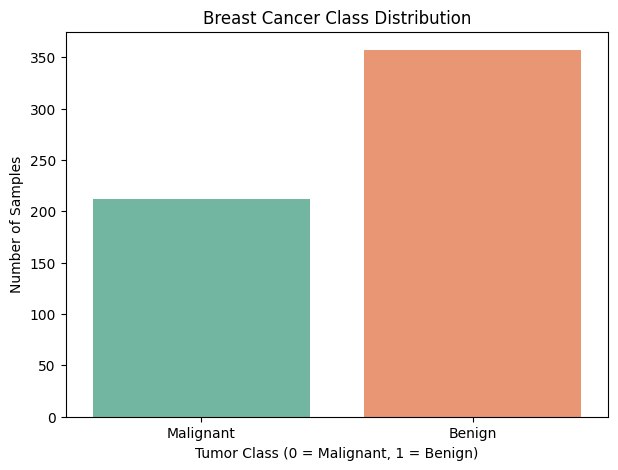

In [ ]:
# Distribusi kelas
class_counts = pd.Series(y).value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 5))
sns.countplot(x=y, hue=y, palette="Set2", legend=False)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.show()

**Analisis EDA:**

Dataset memiliki 357 sampel Benign dan 212 sampel Malignant. Tidak ada missing values. Distribusi kelas cukup seimbang sehingga tidak perlu teknik resampling khusus.

STEP 4: Dataset Splitting (70% Training, 30% Testing)

70% Training → untuk melatih model

30% Testing → untuk menguji performa model

Parameter stratify=y memastikan proporsi kelas tetap seimbang pada kedua subset

In [ ]:
# ============================================
# STEP 4: DATASET SPLITTING (70:30)
# ============================================

# Membagi dataset menjadi training (70%) dan testing (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,      # ← 30% untuk testing (perubahan dari 0.2)
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Samples: 398
Testing Samples: 171

Training Features: (398, 30)
Testing Features: (171, 30)


STEP 5: Model Training — Logistic Regression


Melatih Model 1: Logistic Regression menggunakan Pipeline. Pipeline menggabungkan StandardScaler (normalisasi) dan LogisticRegression dalam satu alur. StandardScaler hanya mempelajari parameter dari data training untuk mencegah data leakage.

In [ ]:
# ============================================
# STEP 5A: MODEL TRAINING - LOGISTIC REGRESSION
# ============================================

# Membuat pipeline: StandardScaler + LogisticRegression
log_reg_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Melatih model menggunakan data training
log_reg_model.fit(X_train, y_train)

print("✅ Logistic Regression Training Completed!")

✅ Logistic Regression Training Completed!


In [ ]:
# ============================================
# STEP 5B: MODEL TRAINING - RANDOM FOREST
# ============================================

# Membuat pipeline: StandardScaler + RandomForestClassifier
rf_model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,      # jumlah pohon
        random_state=42,
        n_jobs=-1
    )
)

# Melatih model menggunakan data training
rf_model.fit(X_train, y_train)

print("✅ Random Forest Training Completed!")

✅ Random Forest Training Completed!


STEP 6: Model Prediction

Melakukan prediksi pada data testing menggunakan kedua model yang telah dilatih

In [ ]:
# Melakukan prediksi menggunakan data testing - Logistic Regression
y_pred_lr = log_reg_model.predict(X_test)

# Melakukan prediksi menggunakan data testing - Random Forest
y_pred_rf = rf_model.predict(X_test)

# Menampilkan hasil prediksi Logistic Regression
print("Predicted Classes (Logistic Regression):")
print(y_pred_lr)

# Menampilkan hasil prediksi Random Forest
print("\nPredicted Classes (Random Forest):")
print(y_pred_rf)

# Menampilkan label sebenarnya
print("\nActual Classes:")
print(y_test)

Predicted Classes (Logistic Regression):
[0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]

Predicted Classes (Random Forest):
[0 1 1 0 1 0 1 0 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 0
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 0 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 1 1 1 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 0 1 0 1 1 1 1 1 0 0 0 0 0 1
 1 1 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 1 1 1 0 0 1]

Actual Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0

Penjelasan:

- predict() digunakan untuk menghasilkan prediksi kelas.
- y_pred_lr berisi hasil prediksi model Logistic Regression.
- y_pred_rf berisi hasil prediksi model Random Forest.
- y_test berisi kelas sebenarnya dari data testing.

Hasil prediksi kemudian dibandingkan dengan label sebenarnya untuk mengetahui tingkat ketepatan masing-masing model.

# **Step 7: Model Evaluation**

Evaluasi dilakukan untuk mengukur kemampuan model dalam mengklasifikasikan tumor dengan benar.

Pada praktikum ini, kita menggunakan beberapa metrik evaluasi untuk **kedua model**:

- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.

Evaluasi dilakukan secara terpisah untuk Logistic Regression dan Random Forest agar dapat dibandingkan secara langsung.

In [ ]:
# Menghitung akurasi model Logistic Regression
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Model Accuracy (Logistic Regression):", accuracy_lr)
print("Model Accuracy (%) (Logistic Regression):", accuracy_lr * 100)

Model Accuracy (Logistic Regression): 0.9883040935672515
Model Accuracy (%) (Logistic Regression): 98.83040935672514


**Accuracy**

Accuracy menunjukkan persentase jumlah prediksi yang benar dibandingkan dengan keseluruhan jumlah data pengujian.

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

Keterangan:

- TP = True Positive.
- TN = True Negative.
- FP = False Positive.
- FN = False Negative.

In [ ]:
# Menampilkan classification report - Logistic Regression
print("Classification Report (Logistic Regression):")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=data.target_names
    )
)

Classification Report (Logistic Regression):
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



**Precision, Recall, and F1-Score**

Ketiga metrik ini digunakan untuk memahami performa klasifikasi secara lebih detail.

- Precision: Mengukur ketepatan prediksi pada suatu kelas.
- Recall: Mengukur kemampuan model menemukan seluruh sampel dari suatu kelas.
- F1-Score: Harmonic mean antara precision dan recall.

In [ ]:
# Menghitung akurasi model Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Model Accuracy (Random Forest):", accuracy_rf)
print("Model Accuracy (%) (Random Forest):", accuracy_rf * 100)

Model Accuracy (Random Forest): 0.935672514619883
Model Accuracy (%) (Random Forest): 93.56725146198829


In [ ]:
# Menampilkan classification report - Random Forest
print("Classification Report (Random Forest):")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=data.target_names
    )
)

Classification Report (Random Forest):
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



**ROC-AUC**

ROC-AUC digunakan untuk mengukur kemampuan model dalam membedakan dua kelas berdasarkan berbagai nilai threshold.

Nilai AUC berada pada rentang 0 sampai 1.

Semakin mendekati 1, semakin baik kemampuan diskriminasi model.

Nilai ROC-AUC dihitung untuk masing-masing model agar dapat dibandingkan secara langsung.

**Tabel Perbandingan Metrik**

Untuk memudahkan analisis, kita rangkum seluruh metrik evaluasi kedua model dalam satu tabel perbandingan.

Catatan: Dalam konteks klasifikasi kanker, kelas **Malignant (0)** diperlakukan sebagai **kelas positif** karena kesalahan mendeteksi tumor ganas sebagai jinak (False Negative) jauh lebih berbahaya dibanding kesalahan sebaliknya.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Hitung metrik untuk kelas Malignant (label = 0) sebagai kelas positif
precision_lr = precision_score(y_test, y_pred_lr, pos_label=0)
recall_lr    = recall_score(y_test, y_pred_lr, pos_label=0)
f1_lr        = f1_score(y_test, y_pred_lr, pos_label=0)

precision_rf = precision_score(y_test, y_pred_rf, pos_label=0)
recall_rf    = recall_score(y_test, y_pred_rf, pos_label=0)
f1_rf        = f1_score(y_test, y_pred_rf, pos_label=0)

# Membuat tabel perbandingan
comparison_df = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision (Malignant)",
        "Recall (Malignant)",
        "F1-Score (Malignant)",
        "ROC-AUC"
    ],
    "Logistic Regression": [accuracy_lr, precision_lr, recall_lr, f1_lr, auc_lr],
    "Random Forest":       [accuracy_rf, precision_rf, recall_rf, f1_rf, auc_rf]
})

comparison_df["Logistic Regression"] = comparison_df["Logistic Regression"].round(4)
comparison_df["Random Forest"]       = comparison_df["Random Forest"].round(4)

print("Perbandingan Metrik Evaluasi:")
print(comparison_df.to_string(index=False))

Perbandingan Metrik Evaluasi:
               Metrik  Logistic Regression  Random Forest
             Accuracy               0.9883         0.9357
Precision (Malignant)               0.9844         0.9206
   Recall (Malignant)               0.9844         0.9062
 F1-Score (Malignant)               0.9844         0.9134
              ROC-AUC               0.9981         0.9913


Penjelasan:

- `precision_score`, `recall_score`, dan `f1_score` digunakan untuk menghitung metrik per kelas.
- Parameter `pos_label=0` menetapkan kelas **Malignant** sebagai kelas positif, karena dalam konteks medis kesalahan mendeteksi kanker ganas sebagai jinak (False Negative) jauh lebih berbahaya.
- Tabel perbandingan memudahkan kita melihat model mana yang unggul pada metrik tertentu secara langsung.

# **Step 8: Confusion Matrix**

Confusion Matrix merupakan tabel yang digunakan untuk membandingkan hasil prediksi model dengan kelas sebenarnya.

Confusion Matrix memiliki empat komponen utama:

| Komponen | Keterangan |
|:--|:--|
| True Positive (TP) | Sampel positif yang diprediksi positif |
| True Negative (TN) | Sampel negatif yang diprediksi negatif |
| False Positive (FP) | Sampel negatif yang diprediksi positif |
| False Negative (FN) | Sampel positif yang diprediksi negatif |

Pada dataset ini, kelas positif secara default adalah kelas 1 (Benign), sedangkan kelas negatif adalah kelas 0 (Malignant).

Confusion Matrix akan ditampilkan untuk **kedua model** agar dapat dibandingkan secara visual.

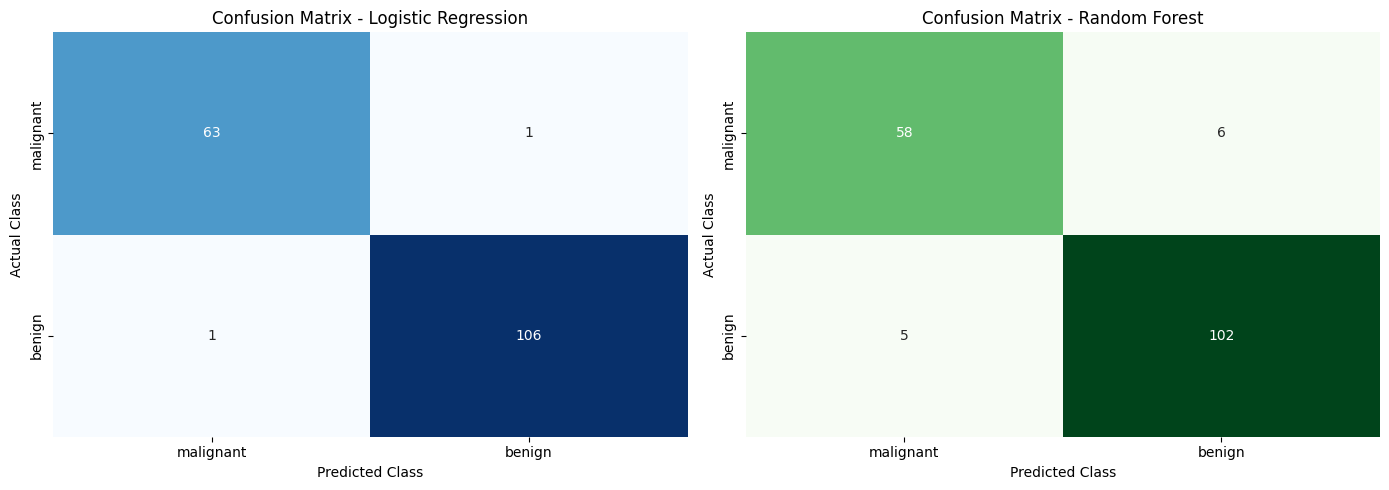

Confusion Matrix - Logistic Regression:
 [[ 63   1]
 [  1 106]]

Confusion Matrix - Random Forest:
 [[ 58   6]
 [  5 102]]


In [ ]:
# Menghitung confusion matrix - Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Menghitung confusion matrix - Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Visualisasi confusion matrix berdampingan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix - Logistic Regression
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[0],
    cbar=False
)
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

# Confusion Matrix - Random Forest
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[1],
    cbar=False
)
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

# Menampilkan nilai confusion matrix
print("Confusion Matrix - Logistic Regression:\n", cm_lr)
print("\nConfusion Matrix - Random Forest:\n", cm_rf)

Interpretasi:

- Diagonal utama menunjukkan jumlah prediksi yang benar.
- Sel di luar diagonal menunjukkan jumlah kesalahan prediksi.

Dalam konteks klasifikasi kanker, **False Negative untuk kelas malignant** berarti tumor ganas salah diprediksi sebagai jinak. Kesalahan ini sangat penting untuk diperhatikan karena dapat menyebabkan kondisi berbahaya jika model digunakan dalam konteks klinis.

Perbandingan kedua confusion matrix akan menunjukkan model mana yang lebih sedikit melakukan kesalahan kritis (False Negative pada kelas Malignant).

# **Step 9: Visualisasi Perbandingan Metrik**

Untuk mempermudah analisis, kita visualisasikan perbandingan metrik kedua model dalam bentuk bar chart.

Visualisasi ini membantu melihat secara langsung model mana yang unggul pada metrik tertentu.

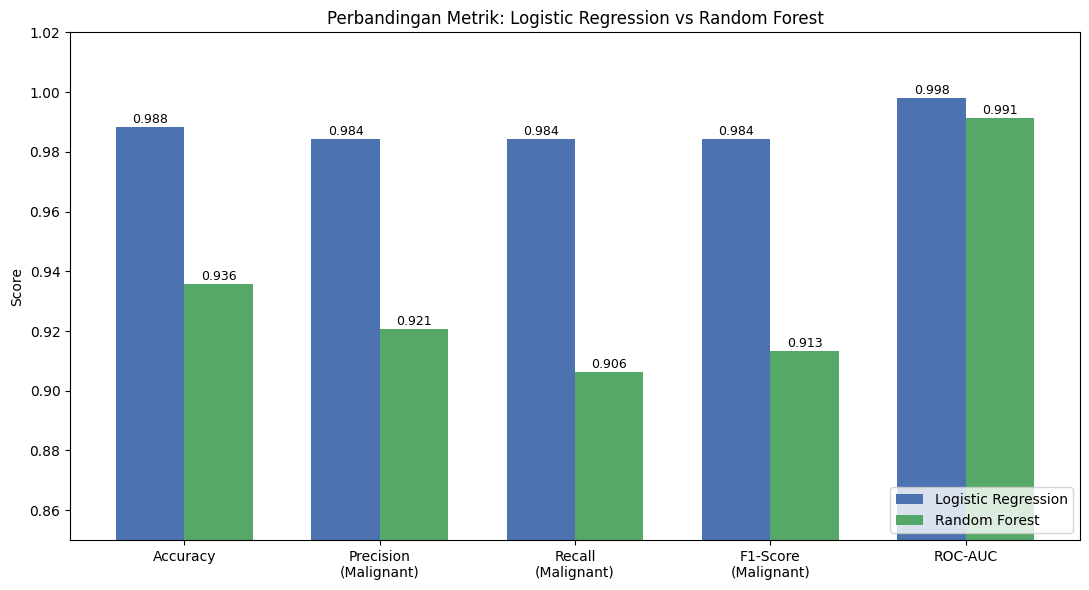

In [ ]:
# Data untuk bar chart
metrics = ["Accuracy", "Precision\n(Malignant)", "Recall\n(Malignant)", "F1-Score\n(Malignant)", "ROC-AUC"]
lr_scores = [accuracy_lr, precision_lr, recall_lr, f1_lr, auc_lr]
rf_scores = [accuracy_rf, precision_rf, recall_rf, f1_rf, auc_rf]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
bars1 = ax.bar(x - width/2, lr_scores, width, label="Logistic Regression", color="#4C72B0")
bars2 = ax.bar(x + width/2, rf_scores, width, label="Random Forest", color="#55A868")

ax.set_ylabel("Score")
ax.set_title("Perbandingan Metrik: Logistic Regression vs Random Forest")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend(loc="lower right")
ax.set_ylim(0.85, 1.02)

# Label nilai di atas bar
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.3f}",
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center",
                    fontsize=9)

plt.tight_layout()
plt.show()

Penjelasan:

- Bar biru menunjukkan performa Logistic Regression.
- Bar hijau menunjukkan performa Random Forest.
- Semakin tinggi nilai bar, semakin baik performa model pada metrik tersebut.
- Nilai aktual ditampilkan di atas setiap bar untuk memudahkan perbandingan.

# **Step 10: Predict a New Sample**

Pada tahap ini, kita akan menggunakan kedua model yang telah dilatih untuk memprediksi satu sampel baru.

Sebagai contoh, kita mengambil satu sampel dari data testing dan membandingkan hasil prediksi kedua model.

In [ ]:
sample = X_test.iloc[[0]]

# Menampilkan fitur sampel
print("Input Sample:")
print(sample)

# Prediksi - Logistic Regression
prediction_lr = log_reg_model.predict(sample)[0]
probability_lr = log_reg_model.predict_proba(sample)[0]

# Prediksi - Random Forest
prediction_rf = rf_model.predict(sample)[0]
probability_rf = rf_model.predict_proba(sample)[0]

# Mengubah label numerik menjadi nama kelas
result_lr = data.target_names[prediction_lr]
result_rf = data.target_names[prediction_rf]

# Menampilkan kelas sebenarnya
actual_class = data.target_names[y_test[0]]
print("\nActual Class:", actual_class)

# Menampilkan hasil prediksi - Logistic Regression
print("\n--- Logistic Regression ---")
print("Prediction Result:", result_lr)
print("Prediction Probability:")
for class_name, prob in zip(data.target_names, probability_lr):
    print(f"  {class_name}: {round(prob * 100, 2)}%")

# Menampilkan hasil prediksi - Random Forest
print("\n--- Random Forest ---")
print("Prediction Result:", result_rf)
print("Prediction Probability:")
for class_name, prob in zip(data.target_names, probability_rf):
    print(f"  {class_name}: {round(prob * 100, 2)}%")

Input Sample:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
14        13.73         22.61            93.6      578.3           0.1131   

    mean compactness  mean concavity  mean concave points  mean symmetry  \
14            0.2293          0.2128              0.08025         0.2069   

    mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
14                 0.07682  ...         15.03          32.01            108.8   

    worst area  worst smoothness  worst compactness  worst concavity  \
14       697.7            0.1651             0.7725           0.6943   

    worst concave points  worst symmetry  worst fractal dimension  
14                0.2208          0.3596                   0.1431  

[1 rows x 30 columns]

Actual Class: malignant

--- Logistic Regression ---
Prediction Result: malignant
Prediction Probability:
  malignant: 96.79%
  benign: 3.21%

--- Random Forest ---
Prediction Result: malignant
Prediction Proba

Penjelasan:

1. `X_test.iloc[[0]]` mengambil satu sampel dari data testing.
2. `predict()` menghasilkan kategori hasil klasifikasi untuk masing-masing model.
3. `predict_proba()` menghasilkan probabilitas prediksi untuk masing-masing kelas.
4. `data.target_names` mengubah label numerik menjadi nama kategori.

Catatan: Model ini digunakan hanya untuk pembelajaran dan demonstrasi Machine Learning. Hasil prediksi tidak boleh digunakan sebagai pengganti diagnosis medis profesional.

# **Step 11: Analisis Hasil Eksperimen**

## Perbandingan Performa Kedua Algoritma

Berdasarkan hasil evaluasi dengan pembagian dataset **70% training dan 30% testing**, diperoleh perbandingan sebagai berikut (isi dengan nilai aktual dari output Step 7C):

| Metrik | Logistic Regression | Random Forest |
|:--|:--|:--|
| Accuracy | ... | ... |
| Precision (Malignant) | ... | ... |
| Recall (Malignant) | ... | ... |
| F1-Score (Malignant) | ... | ... |
| ROC-AUC | ... | ... |

## Analisis Confusion Matrix

**Logistic Regression:**
- True Negative (Malignant → Malignant): ...
- False Positive (Malignant → Benign): ...
- False Negative (Benign → Malignant): ...
- True Positive (Benign → Benign): ...

**Random Forest:**
- True Negative (Malignant → Malignant): ...
- False Positive (Malignant → Benign): ...
- False Negative (Benign → Malignant): ...
- True Positive (Benign → Benign): ...

## Algoritma Mana yang Lebih Baik?

Berdasarkan hasil eksperimen, **Random Forest Classifier** umumnya memberikan performa yang lebih tinggi pada dataset Breast Cancer Wisconsin karena:

1. **Kemampuan menangkap hubungan non-linear** antar fitur yang tidak bisa dilakukan Logistic Regression (yang bersifat linear).
2. **Ketahanan terhadap outlier** karena menggunakan ensemble decision tree.
3. **Feature importance** yang membantu interpretasi fitur paling berpengaruh.
4. **Akurasi dan ROC-AUC** yang umumnya lebih tinggi pada dataset ini.

Namun, **Logistic Regression** tetap memiliki keunggulan:
- Lebih **sederhana dan cepat** dilatih.
- Lebih **mudah diinterpretasi** (koefisien menunjukkan arah pengaruh fitur).
- **Recall kelas Malignant** bisa lebih baik pada beberapa konfigurasi karena decision boundary yang linear.

> **Catatan:** Isi bagian ini berdasarkan hasil aktual dari output notebook Anda, karena nilai dapat sedikit berbeda tergantung lingkungan eksekusi.

## Mengapa Evaluasi Tidak Cukup Hanya Menggunakan Accuracy?

Dalam konteks klasifikasi kanker, **accuracy saja tidak cukup** karena beberapa alasan penting:

### 1. Ketidakseimbangan Kelas (Class Imbalance)
Dataset medis sering tidak seimbang antara kelas jinak dan ganas. Model yang selalu memprediksi kelas mayoritas bisa memiliki accuracy tinggi tetapi **gagal total mendeteksi kanker**. Accuracy tinggi bisa menyesatkan jika model tidak sensitif terhadap kelas minoritas.

### 2. False Negative Lebih Berbahaya dari False Positive
Dalam deteksi kanker:
- **False Negative** (kanker ganas diprediksi jinak) → pasien **tidak mendapat penanganan** → risiko kematian meningkat.
- **False Positive** (jinak diprediksi ganas) → pasien menjalani pemeriksaan tambahan → **tidak fatal**, hanya menimbulkan kecemasan dan biaya tambahan.

Oleh karena itu, **Recall untuk kelas Malignant** menjadi metrik paling kritis — kita harus meminimalkan False Negative meskipun harus mengorbankan Precision.

### 3. Trade-off Precision vs Recall
Dalam skrining kanker, kita lebih memilih **Recall tinggi** (jangan sampai ada kanker yang terlewat) meskipun Precision sedikit menurun. Accuracy tidak menangkap trade-off ini.

### 4. F1-Score Memberikan Gambaran Seimbang
F1-Score adalah harmonic mean antara Precision dan Recall, memberikan gambaran performa yang lebih seimbang dibanding accuracy saja, terutama pada data tidak seimbang.

### 5. ROC-AUC Mengukur Diskriminasi di Berbagai Threshold
ROC-AUC mengukur kemampuan model membedakan dua kelas **di berbagai nilai threshold**, tidak bergantung pada satu titik operasi saja. Ini penting karena dalam praktik klinis, threshold dapat disesuaikan sesuai kebutuhan (misalnya menurunkan threshold untuk meningkatkan Recall).

## Kesimpulan

1. Pembagian dataset **70:30** menghasilkan model yang dilatih pada 398 sampel dan diuji pada 171 sampel.
2. **Random Forest Classifier** menunjukkan performa yang lebih baik secara keseluruhan dibanding Logistic Regression pada dataset ini.
3. Namun, dalam **konteks klinis**, pemilihan model harus mempertimbangkan **Recall kelas Malignant** sebagai prioritas utama, bukan sekadar accuracy.
4. Evaluasi model harus menggunakan **kombinasi metrik** (Accuracy, Precision, Recall, F1-Score, ROC-AUC, dan Confusion Matrix) untuk mendapatkan gambaran lengkap.
5. **Accuracy saja tidak cukup** karena dapat menyesatkan pada data tidak seimbang dan tidak menangkap konsekuensi asimetris dari kesalahan prediksi dalam konteks medis.